In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Machine Learning
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

In [3]:
# Load dataset

df = pd.read_csv("Bengaluru_House_Data.csv")

print(df.head())
print(df.shape)
print(df.info())
print(df.describe())

              area_type   availability                  location       size  \
0  Super built-up  Area         19-Dec  Electronic City Phase II      2 BHK   
1            Plot  Area  Ready To Move          Chikka Tirupathi  4 Bedroom   
2        Built-up  Area  Ready To Move               Uttarahalli      3 BHK   
3  Super built-up  Area  Ready To Move        Lingadheeranahalli      3 BHK   
4  Super built-up  Area  Ready To Move                  Kothanur      2 BHK   

   society total_sqft  bath  balcony   price  
0  Coomee        1056   2.0      1.0   39.07  
1  Theanmp       2600   5.0      3.0  120.00  
2      NaN       1440   2.0      3.0   62.00  
3  Soiewre       1521   3.0      1.0   95.00  
4      NaN       1200   2.0      1.0   51.00  
(13320, 9)
<class 'pandas.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  str    
 1   a

In [4]:
# Check missing values

print(df.isnull().sum())

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64


In [5]:
# Check duplicate records

print("Duplicates:", df.duplicated().sum())

df.drop_duplicates(inplace=True)

Duplicates: 529


In [6]:
# Check percentage of missing values

missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print(missing_percentage.sort_values(ascending=False))

society         41.654288
balcony          4.729888
bath             0.570714
size             0.125088
location         0.007818
area_type        0.000000
availability     0.000000
total_sqft       0.000000
price            0.000000
dtype: float64


In [7]:
# Extract BHK from size column

df['bhk'] = (
    df['size']
    .str.extract(r'(\d+)')
    .astype(float)
)

print(df[['size', 'bhk']].head())

        size  bhk
0      2 BHK  2.0
1  4 Bedroom  4.0
2      3 BHK  3.0
3      3 BHK  3.0
4      2 BHK  2.0


In [8]:
def convert_sqft(value):

    try:
        value = str(value)

        if '-' in value:
            values = value.split('-')

            return (
                float(values[0]) +
                float(values[1])
            ) / 2

        return float(value)

    except:
        return np.nan


df['total_sqft'] = df['total_sqft'].apply(convert_sqft)

print(df['total_sqft'].head())

0    1056.0
1    2600.0
2    1440.0
3    1521.0
4    1200.0
Name: total_sqft, dtype: float64


In [9]:
# Fill missing numerical values

df['bath'] = df['bath'].fillna(df['bath'].median())

df['balcony'] = df['balcony'].fillna(
    df['balcony'].median()
)

# Fill missing categorical values

df['location'] = df['location'].fillna('Unknown')

# Remove rows where important features are missing

df.dropna(
    subset=['total_sqft', 'bhk', 'price'],
    inplace=True
)

print(df.isnull().sum())

area_type          0
availability       0
location           0
size               0
society         5295
total_sqft         0
bath               0
balcony            0
price              0
bhk                0
dtype: int64


In [10]:
df.drop(
    columns=['society', 'availability', 'size'],
    inplace=True
)

print(df.head())

              area_type                  location  total_sqft  bath  balcony  \
0  Super built-up  Area  Electronic City Phase II      1056.0   2.0      1.0   
1            Plot  Area          Chikka Tirupathi      2600.0   5.0      3.0   
2        Built-up  Area               Uttarahalli      1440.0   2.0      3.0   
3  Super built-up  Area        Lingadheeranahalli      1521.0   3.0      1.0   
4  Super built-up  Area                  Kothanur      1200.0   2.0      1.0   

    price  bhk  
0   39.07  2.0  
1  120.00  4.0  
2   62.00  3.0  
3   95.00  3.0  
4   51.00  2.0  


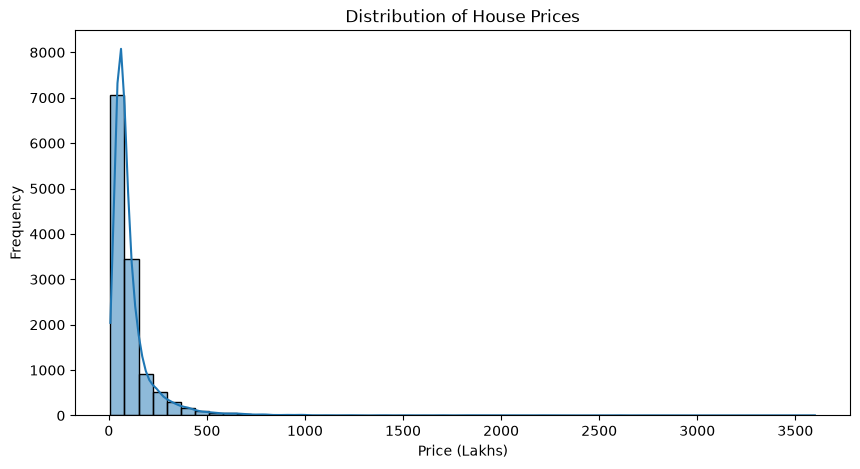

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['price'],
    kde=True,
    bins=50
)

plt.title("Distribution of House Prices")
plt.xlabel("Price (Lakhs)")
plt.ylabel("Frequency")

plt.show()

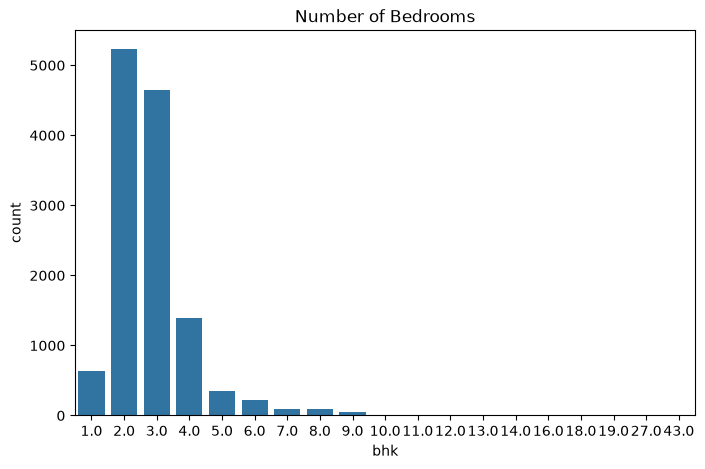

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='bhk'
)

plt.title("Number of Bedrooms")

plt.show()

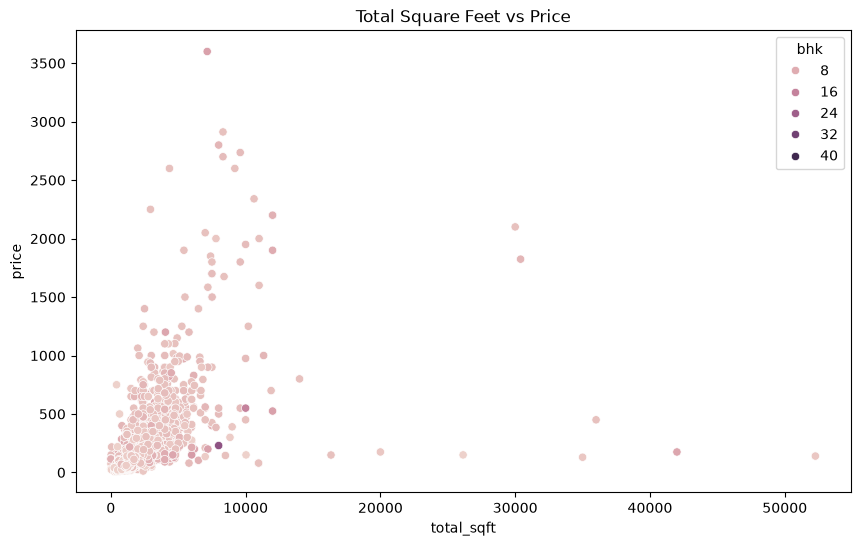

In [13]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='total_sqft',
    y='price',
    hue='bhk'
)

plt.title("Total Square Feet vs Price")

plt.show()

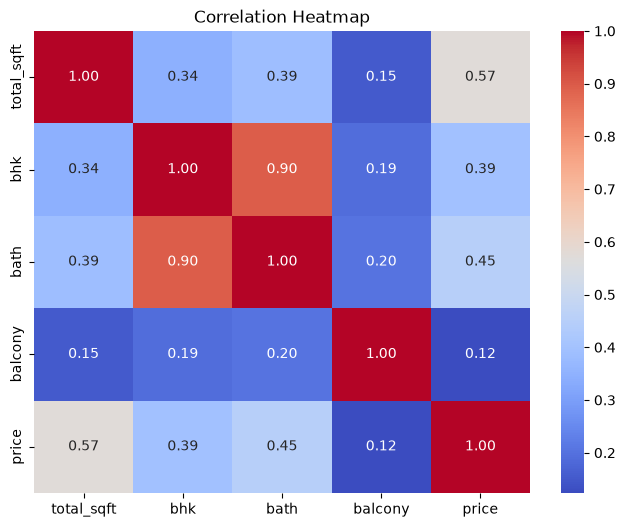

In [17]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df[['total_sqft', 'bhk', 'bath',
        'balcony', 'price']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

In [18]:
df = df[
    (df['total_sqft'] / df['bhk']) >= 300
]

# Remove properties with unusually high bathroom counts

df = df[
    df['bath'] <= df['bhk'] + 2
]

print("Shape after outlier removal:", df.shape)

Shape after outlier removal: (11986, 7)


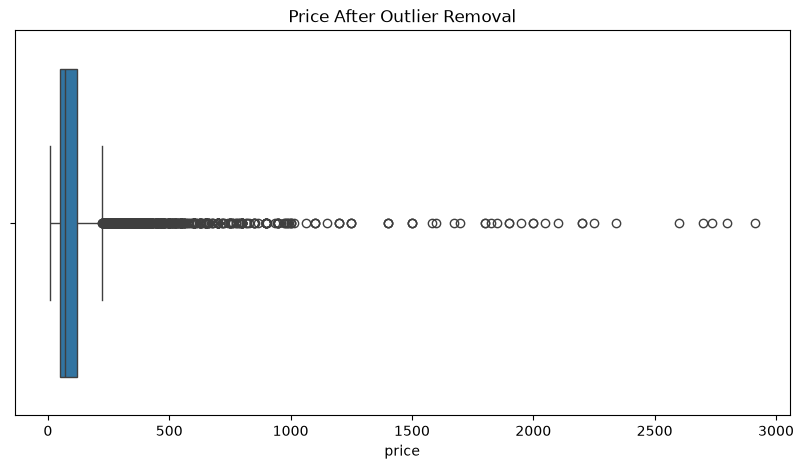

In [19]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df['price']
)

plt.title("Price After Outlier Removal")

plt.show()

In [18]:
X = df.drop('price', axis=1)

y = df['price']

print("Features:")
print(X.head())

print("Target:")
print(y.head())

Features:
              area_type                  location  total_sqft  bath  balcony  \
0  Super built-up  Area  Electronic City Phase II      1056.0   2.0      1.0   
1            Plot  Area          Chikka Tirupathi      2600.0   5.0      3.0   
2        Built-up  Area               Uttarahalli      1440.0   2.0      3.0   
3  Super built-up  Area        Lingadheeranahalli      1521.0   3.0      1.0   
4  Super built-up  Area                  Kothanur      1200.0   2.0      1.0   

   bhk  
0  2.0  
1  4.0  
2  3.0  
3  3.0  
4  2.0  
Target:
0     39.07
1    120.00
2     62.00
3     95.00
4     51.00
Name: price, dtype: float64


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)

print("Testing data:", X_test.shape)

Training data: (10183, 6)
Testing data: (2546, 6)


In [20]:
categorical_features = [
    'area_type',
    'location'
]

numerical_features = [
    'total_sqft',
    'bhk',
    'bath',
    'balcony'
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'numerical',
            StandardScaler(),
            numerical_features
        )
    ]
)

In [21]:
models = {

    'Linear Regression': LinearRegression(),

    'Ridge Regression': Ridge(alpha=1.0),

    'Decision Tree': DecisionTreeRegressor(
        random_state=42
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    'Extra Trees': ExtraTreesRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

In [22]:
results = {}

trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    pipeline = Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('model', model)
        ]
    )

    # Train model

    pipeline.fit(X_train, y_train)

    # Prediction

    y_pred = pipeline.predict(X_test)

    # Evaluation metrics

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results[name] = {
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    }

    trained_models[name] = pipeline

    print("MAE:", mae)
    print("RMSE:", rmse)
    print("R2 Score:", r2)


Training: Linear Regression
MAE: 45.19738328500476
RMSE: 124.69346540978616
R2 Score: 0.45298259830066145

Training: Ridge Regression
MAE: 43.94923431506928
RMSE: 122.92394688057178
R2 Score: 0.4683978296924556

Training: Decision Tree
MAE: 41.128343422136034
RMSE: 131.76978924275733
R2 Score: 0.3891347006789131

Training: Random Forest
MAE: 34.97836865425529
RMSE: 108.61517994175637
R2 Score: 0.584955364592424

Training: Extra Trees
MAE: 33.18838551269506
RMSE: 104.35745532200303
R2 Score: 0.6168571600622156


In [23]:
comparison = pd.DataFrame(results).T

comparison = comparison.sort_values(
    by='R2 Score',
    ascending=False
)

print(comparison)

                         MAE           MSE        RMSE  R2 Score
Extra Trees        33.188386  10890.478481  104.357455  0.616857
Random Forest      34.978369  11797.257314  108.615180  0.584955
Ridge Regression   43.949234  15110.296717  122.923947  0.468398
Linear Regression  45.197383  15548.460316  124.693465  0.452983
Decision Tree      41.128343  17363.277357  131.769789  0.389135


In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=comparison.index,
    y=comparison['R2 Score'],
    hue=comparison.index,
    palette='viridis',
    legend=False
)

plt.title("Model Accuracy Comparison")

plt.xlabel("Machine Learning Algorithms")

plt.ylabel("R2 Score")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

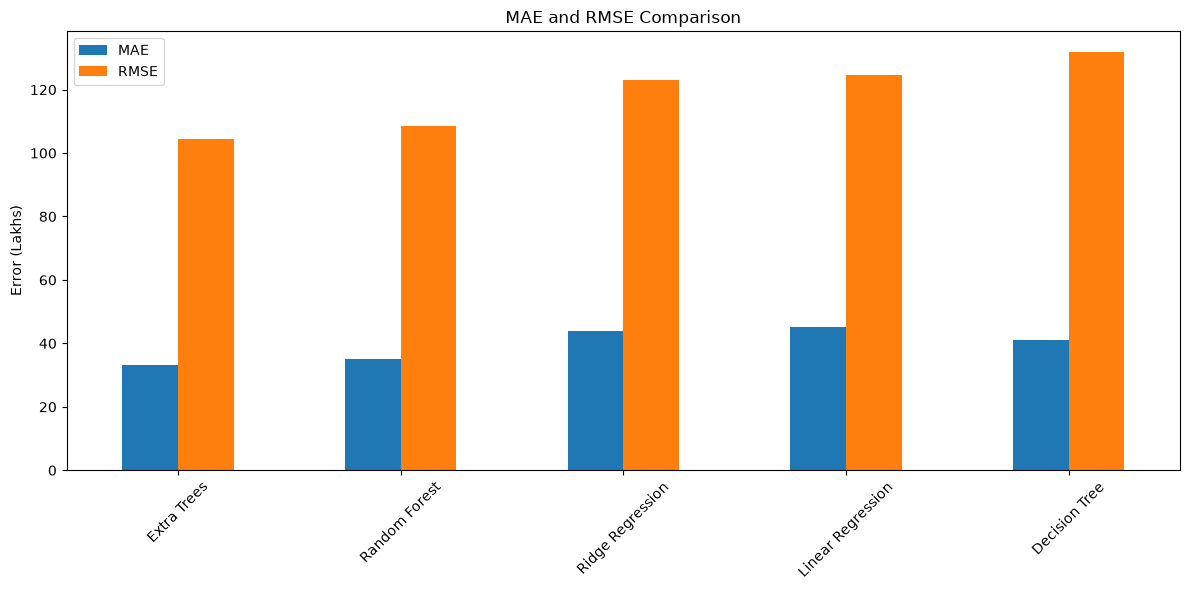

In [24]:
comparison[['MAE', 'RMSE']].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("MAE and RMSE Comparison")

plt.ylabel("Error (Lakhs)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [25]:
best_model_name = comparison['R2 Score'].idxmax()

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

print("Best R2 Score:",
      comparison.loc[best_model_name, 'R2 Score'])

Best Model: Extra Trees
Best R2 Score: 0.6168571600622156


In [29]:
rf_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),

        (
            'model',
            RandomForestRegressor(
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

param_grid = {

    'model__n_estimators': [100, 200],

    'model__max_depth': [None, 15, 25],

    'model__min_samples_split': [2, 5],

    'model__min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV R2 Score:")
print(grid_search.best_score_)

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best Parameters:
{'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best CV R2 Score:
0.6027362042555525


In [31]:
tuned_model = grid_search.best_estimator_

tuned_predictions = tuned_model.predict(X_test)

print(
    "Tuned R2 Score:",
    r2_score(y_test, tuned_predictions)
)

print(
    "Tuned MAE:",
    mean_absolute_error(y_test, tuned_predictions)
)

print(
    "Tuned RMSE:",
    np.sqrt(
        mean_squared_error(y_test, tuned_predictions)
    )
)

Tuned R2 Score: 0.596100161614635
Tuned MAE: 34.765541929053626
Tuned RMSE: 107.1469870567254


In [32]:
# Save model and input options

model_data = {
    'model': tuned_model,
    'locations': sorted(df['location'].unique().tolist()),
    'area_types': sorted(df['area_type'].unique().tolist()),
    'features': X.columns.tolist()
}

joblib.dump(
    model_data,
    'house_price_model.pkl'
)

print("Model saved successfully!")

Model saved successfully!


In [33]:
# Load saved model

loaded_data = joblib.load('house_price_model.pkl')

loaded_model = loaded_data['model']

# Create sample house

new_house = pd.DataFrame({

    'area_type': ['Super built-up  Area'],

    'location': ['Whitefield'],

    'total_sqft': [1200],

    'bhk': [2],

    'bath': [2],

    'balcony': [1]

})

# Predict house price

predicted_price = loaded_model.predict(new_house)

print(
    "Predicted House Price:",
    round(predicted_price[0], 2),
    "Lakhs"
)

Predicted House Price: 48.28 Lakhs
